Time - Series Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("../data/processed/train_clean.csv")

In [3]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
df.isnull().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [5]:
df=df.sort_values(
    ["store","item","date"]
).reset_index(drop=True)

In [6]:
group = df.groupby(["store","item"])["sales"]

for lag in [1,7,14,28,30]:
    df[f"lag_{lag}"] = group.shift(lag)

In [7]:
df

,date,store,item,sales,lag_1,lag_7,lag_14,lag_28,lag_30
0,2013-01-01,1,1,13,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,1,1,11,13.0,NaN,NaN,NaN,NaN
2,2013-01-03,1,1,14,11.0,NaN,NaN,NaN,NaN
3,2013-01-04,1,1,13,14.0,NaN,NaN,NaN,NaN
4,2013-01-05,1,1,10,13.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
912995,2017-12-27,10,50,63,41.0,51.0,67.0,76.0,75.0
912996,2017-12-28,10,50,59,63.0,63.0,72.0,73.0,68.0
912997,2017-12-29,10,50,74,59.0,75.0,72.0,66.0,76.0
912998,2017-12-30,10,50,62,74.0,70.0,52.0,49.0,73.0


In [10]:
grouped = df.groupby(
    ["store", "item"]
)["sales"]


for window in [7, 14, 28, 30]:
    df[f"rolling_mean_{window}"] = grouped.transform(lambda x: x.shift(1).rolling(window=window).mean())

    df[f"rolling_std_{window}"] = grouped.transform(lambda x: x.shift(1).rolling(window=window).std())

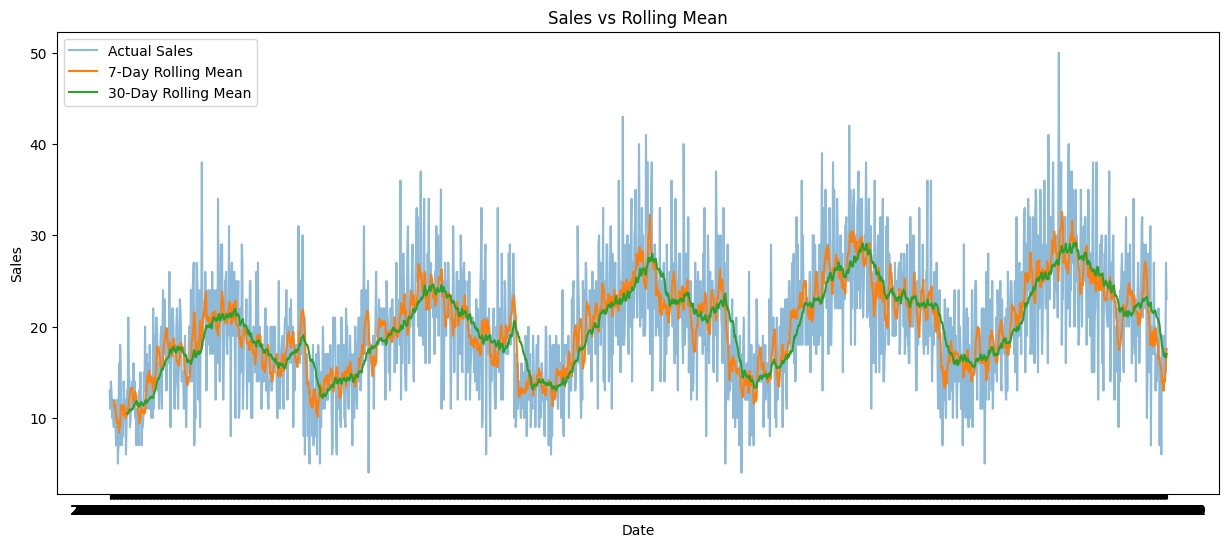

In [ ]:
sample = df[
    (df["store"] == 1) &
    (df["item"] == 1)
].copy()
plt.figure(figsize=(15, 6))

plt.plot(
    sample["date"],
    sample["sales"],
    label="Actual Sales",
    alpha=0.5
)

plt.plot(
    sample["date"],
    sample["rolling_mean_7"],
    label="7-Day Rolling Mean"
)

plt.plot(
    sample["date"],
    sample["rolling_mean_30"],
    label="30-Day Rolling Mean"
)

plt.title("Sales vs Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.show()

In [12]:
grouped = df.groupby(
    ["store", "item"]
)["sales"]

df["expanding_mean"] = (
    grouped.transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

In [13]:
df["expanding_std"] = (
    grouped.transform(
        lambda x: x.shift(1).expanding().std()
    )
)

In [16]:

df["date"]=pd.to_datetime(df["date"])

df["year"] = df["date"].dt.year

df["month"] = df["date"].dt.month

df["day"] = df["date"].dt.day

df["day_of_week"] = (
    df["date"].dt.dayofweek
)

df["day_of_year"] = (
    df["date"].dt.dayofyear
)

df["week_of_year"] = (
    df["date"].dt.isocalendar().week.astype(int)
)

df["quarter"] = (
    df["date"].dt.quarter
)

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

df["is_month_start"] = (
    df["date"].dt.is_month_start.astype(int)
)

df["is_month_end"] = (
    df["date"].dt.is_month_end.astype(int)
)

In [17]:
df["week_sin"] = np.sin(
    2 * np.pi * df["day_of_week"] / 7
)

df["week_cos"] = np.cos(
    2 * np.pi * df["day_of_week"] / 7
)

In [18]:
df["year_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["year_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

In [23]:
from src.features.time_series_features import (
    create_time_series_features
)
df = pd.read_csv(
    "../data/processed/train_clean.csv",
    parse_dates=["date"]
)
featured_df = create_time_series_features(df)
print("Original shape:", df.shape)
print("Featured shape:", featured_df.shape)
featured_df.head()

ModuleNotFoundError: No module named 'src'

In [22]:
import os
print(os.getcwd())
print(os.listdir("."))   # do you see 'src' here?

c:\Users\Admin\Desktop\Demand-Forcast\notebooks
['01_data_understanding.ipynb', '02_data_preprocessing.ipynb', '03_exploratory_data_analysis.ipynb', '04_time_series_features.ipynb']


In [24]:
import os, sys
print("CWD:", os.getcwd())
print("Has src:", os.path.isdir("src"))
print("Has src/features:", os.path.isdir("src/features"))
print("Has target file:", os.path.isfile("src/features/time_series_features.py"))
print("sys.path[0]:", sys.path[0])

CWD: c:\Users\Admin\Desktop\Demand-Forcast\notebooks
Has src: False
Has src/features: False
Has target file: False
sys.path[0]: c:\Users\Admin\AppData\Local\Programs\Python\Python314\python314.zip
